# Data Loading

In [1]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.278481
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,5.168612
948,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.418645
3160,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.545432
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.169421


# Prediction Analysis

## Metrics

In [2]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.432503,0.363924,0.240154,0.490055
Split 1,0.414569,0.418538,0.323351,0.568639
Split 2,0.496962,0.364053,0.222316,0.471504
Split 3,0.422116,0.415670,0.326962,0.571806
Split 4,0.425493,0.374785,0.275439,0.524822
Split 5,0.432708,0.395789,0.300089,0.547804
Split 6,0.432740,0.365826,0.239508,0.489396
Split 7,0.353372,0.386790,0.279376,0.528560
Split 8,0.441909,0.377991,0.289381,0.537941
Split 9,0.489999,0.356031,0.241787,0.491718


# Graph

Text(0, 0.5, 'predicted pIC50')

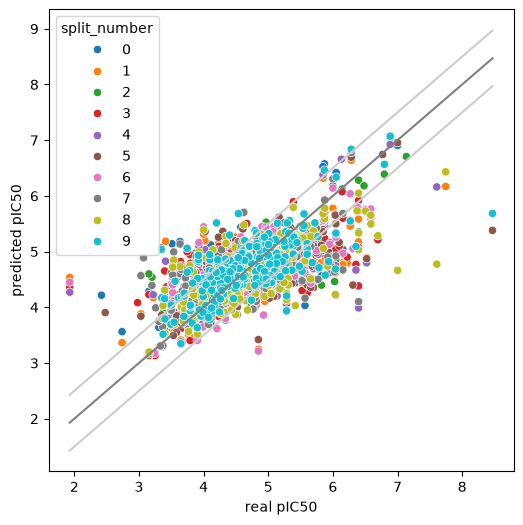

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

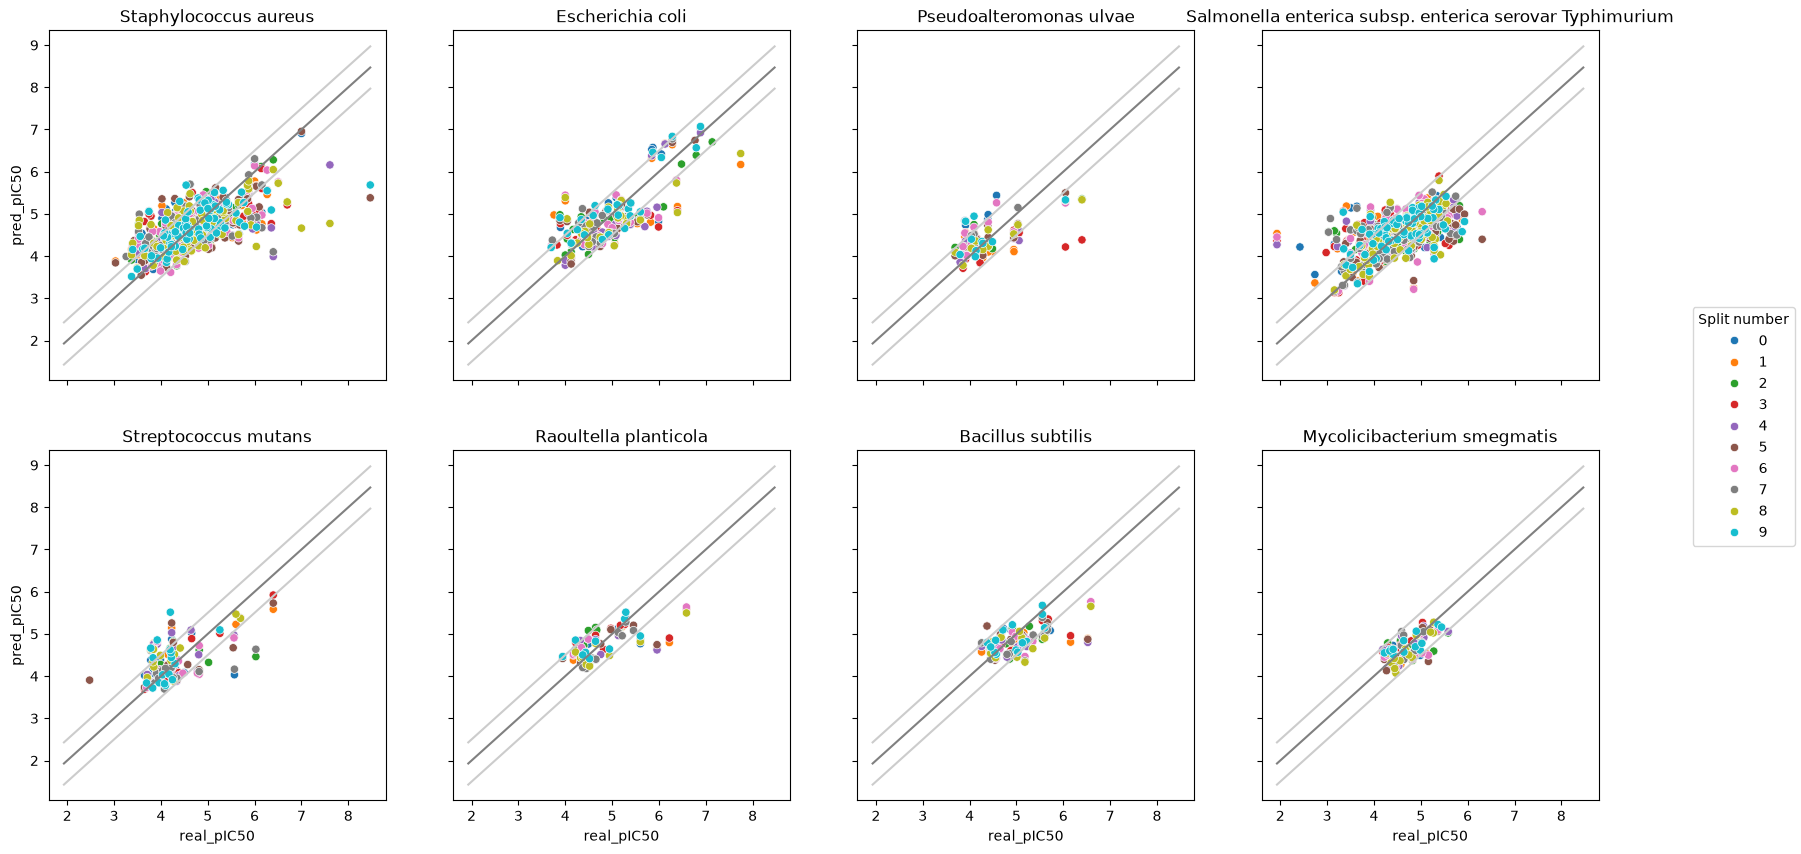

In [4]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [5]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.443,0.085,0.388,0.042,0.534,0.073
Escherichia coli,0.501,0.154,0.381,0.039,0.486,0.072
Pseudoalteromonas ulvae,0.183,0.642,0.379,0.101,0.489,0.162
Salmonella enterica subsp. enterica serovar Typhimurium,0.322,0.083,0.418,0.043,0.564,0.056
Streptococcus mutans,0.141,0.565,0.384,0.084,0.501,0.121
Raoultella planticola,0.375,0.227,0.309,0.063,0.440,0.105
Bacillus subtilis,0.229,0.218,0.356,0.071,0.475,0.119
Mycolicibacterium smegmatis,0.295,0.285,0.228,0.040,0.270,0.043


In [6]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.4390814459197777
MAE 0.38775969485641
MSE 0.28942195203585697
RMSE 0.5379795089367782
..............
Escherichia coli
r2_score 0.5449207749041467
MAE 0.38014812296816375
MSE 0.24140601043987692
RMSE 0.49133085638892754
..............
Pseudoalteromonas ulvae
r2_score 0.34754408194015096
MAE 0.377834344600609
MSE 0.2609936793022685
RMSE 0.5108754048711569
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.33033018743981535
MAE 0.4176525751409286
MSE 0.3219723344993642
RMSE 0.5674260608214644
..............
Streptococcus mutans
r2_score 0.31590120542264655
MAE 0.3785653694898311
MSE 0.2579648866134297
RMSE 0.5079024380857309
..............
Raoultella planticola
r2_score 0.4325846566421434
MAE 0.3087577465777599
MSE 0.20391074662445954
RMSE 0.4515647756684079
..............
Bacillus subtilis
r2_score 0.23175532250918118
MAE 0.3560277876833836
MSE 0.23603234879523788
RMSE 0.48583160538939607
..............
Mycolicibacterium sme